In [1]:
import numpy as np
from scipy.sparse.linalg import svds
import fastplotlib as fpl
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from itertools import product
from typing import *
from time import time
import tifffile
import h5py
from ipywidgets import HBox, VBox

No windowing system present. Using surfaceless platform
No config found!
No config found!


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Available devices:
✅ (default) | Tesla V100-SXM2-32GB | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 16.0.6, 256 bits) | CPU | Vulkan | Mesa 24.0.0-devel (git-3ca1f35cbf) (LLVM 16.0.6)
❗ | Tesla V100-SXM2-32GB/PCIe/SSE2 | Unknown | OpenGL | 


In [2]:
import scipy
import scipy.integrate
from pydmd import DMD, BOPDMD
from pydmd.preprocessing import hankel_preprocessing
from pydmd.plotter import plot_modes_2D

In [3]:
f = h5py.File("/mnt/home/kkolar/data/000168/jGCaMP8m/jGCaMP8m_ANM472179_cell01.nwb")

In [4]:
f.keys()

<KeysViewHDF5 ['acquisition', 'analysis', 'file_create_date', 'general', 'identifier', 'intervals', 'processing', 'session_description', 'session_start_time', 'specifications', 'stimulus', 'timestamps_reference_time']>

In [5]:
f["acquisition"].keys()

<KeysViewHDF5 ['Registered movie 0', 'Registered movie 1', 'Registered movie 2', 'loose seal recording for movie 0', 'loose seal recording for movie 1', 'loose seal recording for movie 2', 'loose seal stimulus for movie 0', 'loose seal stimulus for movie 1', 'loose seal stimulus for movie 2']>

In [6]:
movie = f["acquisition"]["Registered movie 0"]["data"][:5000]

In [7]:
iw = fpl.ImageWidget(movie, cmap="gnuplot2")
iw.show()

RFBOutputContext()

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:34: UserWarning: converting float64 array to float32
  warn(f"converting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [8]:
movie.shape

(5000, 512, 128)

In [70]:
movie = movie[:2_000].copy()

In [10]:
frames = [f for f in movie]

In [11]:
frames[0].shape

(512, 128)

In [12]:
# dmd = DMD(svd_rank=3, tlsq_rank=2, exact=True, opt=True)
# dmd.fit(frames)

In [71]:
X = movie.reshape(movie.shape[0], movie.shape[1] * movie.shape[2])

In [72]:
X.shape

(2000, 65536)

In [74]:
delay = 2
t = np.arange(0, 2000)
delay_t = t[: -delay + 1]

dmd = BOPDMD(
    svd_rank=8, num_trials=0, eig_constraints={"imag", "conjugate_pairs"}
)
delay_dmd = hankel_preprocessing(dmd, d=delay)
delay_dmd.fit(X.T, t=delay_t)

/mnt/home/kkolar/repos/PyDMD/pydmd/bopdmd.py:751: UserWarning: Initial trial of Optimized DMD failed to converge. Consider re-adjusting your variable projection parameters with the varpro_opts_dict and consider setting verbose=True.
  warnings.warn(msg)


In [17]:
dmd.modes.shape

(131072, 3)

In [18]:
512*128*2

131072

In [75]:
shape = (1024, 128)
iw = fpl.ImageWidget([m.reshape(shape).astype(np.float32) for m in dmd.modes.T], cmap="gnuplot2")
iw.show()

/tmp/ipykernel_257612/2972351604.py:2: ComplexWarning: Casting complex values to real discards the imaginary part
  iw = fpl.ImageWidget([m.reshape(shape).astype(np.float32) for m in dmd.modes.T], cmap="gnuplot2")


RFBOutputContext()

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:34: UserWarning: converting float64 array to float32
  warn(f"converting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [34]:
dmd.modes[0].max()

(0.0010781680041855755+3.592186053468774e-22j)

In [76]:
dmd.reconstructed_data.shape

(131072, 1999)

In [77]:
iw = fpl.ImageWidget(np.dstack([r.reshape(shape).astype(np.float32) for r in dmd.reconstructed_data.T]).T, cmap="gnuplot2")
iw.show()

/tmp/ipykernel_257612/2174582755.py:1: ComplexWarning: Casting complex values to real discards the imaginary part
  iw = fpl.ImageWidget(np.dstack([r.reshape(shape).astype(np.float32) for r in dmd.reconstructed_data.T]).T, cmap="gnuplot2")


RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [28]:
import pickle

In [22]:
movie_mean = movie.mean(axis=(1, 2))

In [78]:
from tslearn.preprocessing import TimeSeriesScalerMinMax

/mnt/home/kkolar/venvs/mescore/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/mnt/home/kkolar/venvs/mescore/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/mnt/home/kkolar/venvs/mescore/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/mnt/home/kkolar/venvs/mescore/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/mnt/home/kkolar/venvs/mescore/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/mnt/home/kkolar/venvs/mescore/lib/python3.11/site-

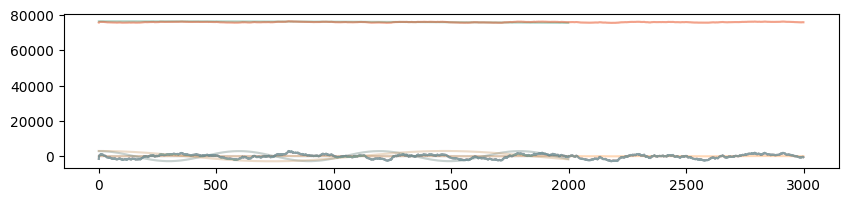

In [79]:
fig = plt.figure(figsize=(10, 2))
for t in dmd.dynamics[1:]:
    
    plt.plot(t, alpha=0.2)
    plt.plot(TimeSeriesScalerMinMax((t.real.min(), t.real.max())).fit_transform(movie_mean.reshape(1, -1)).ravel(), alpha=0.3)
    # plt.show()

In [80]:
from pydmd.plotter import plot_summary

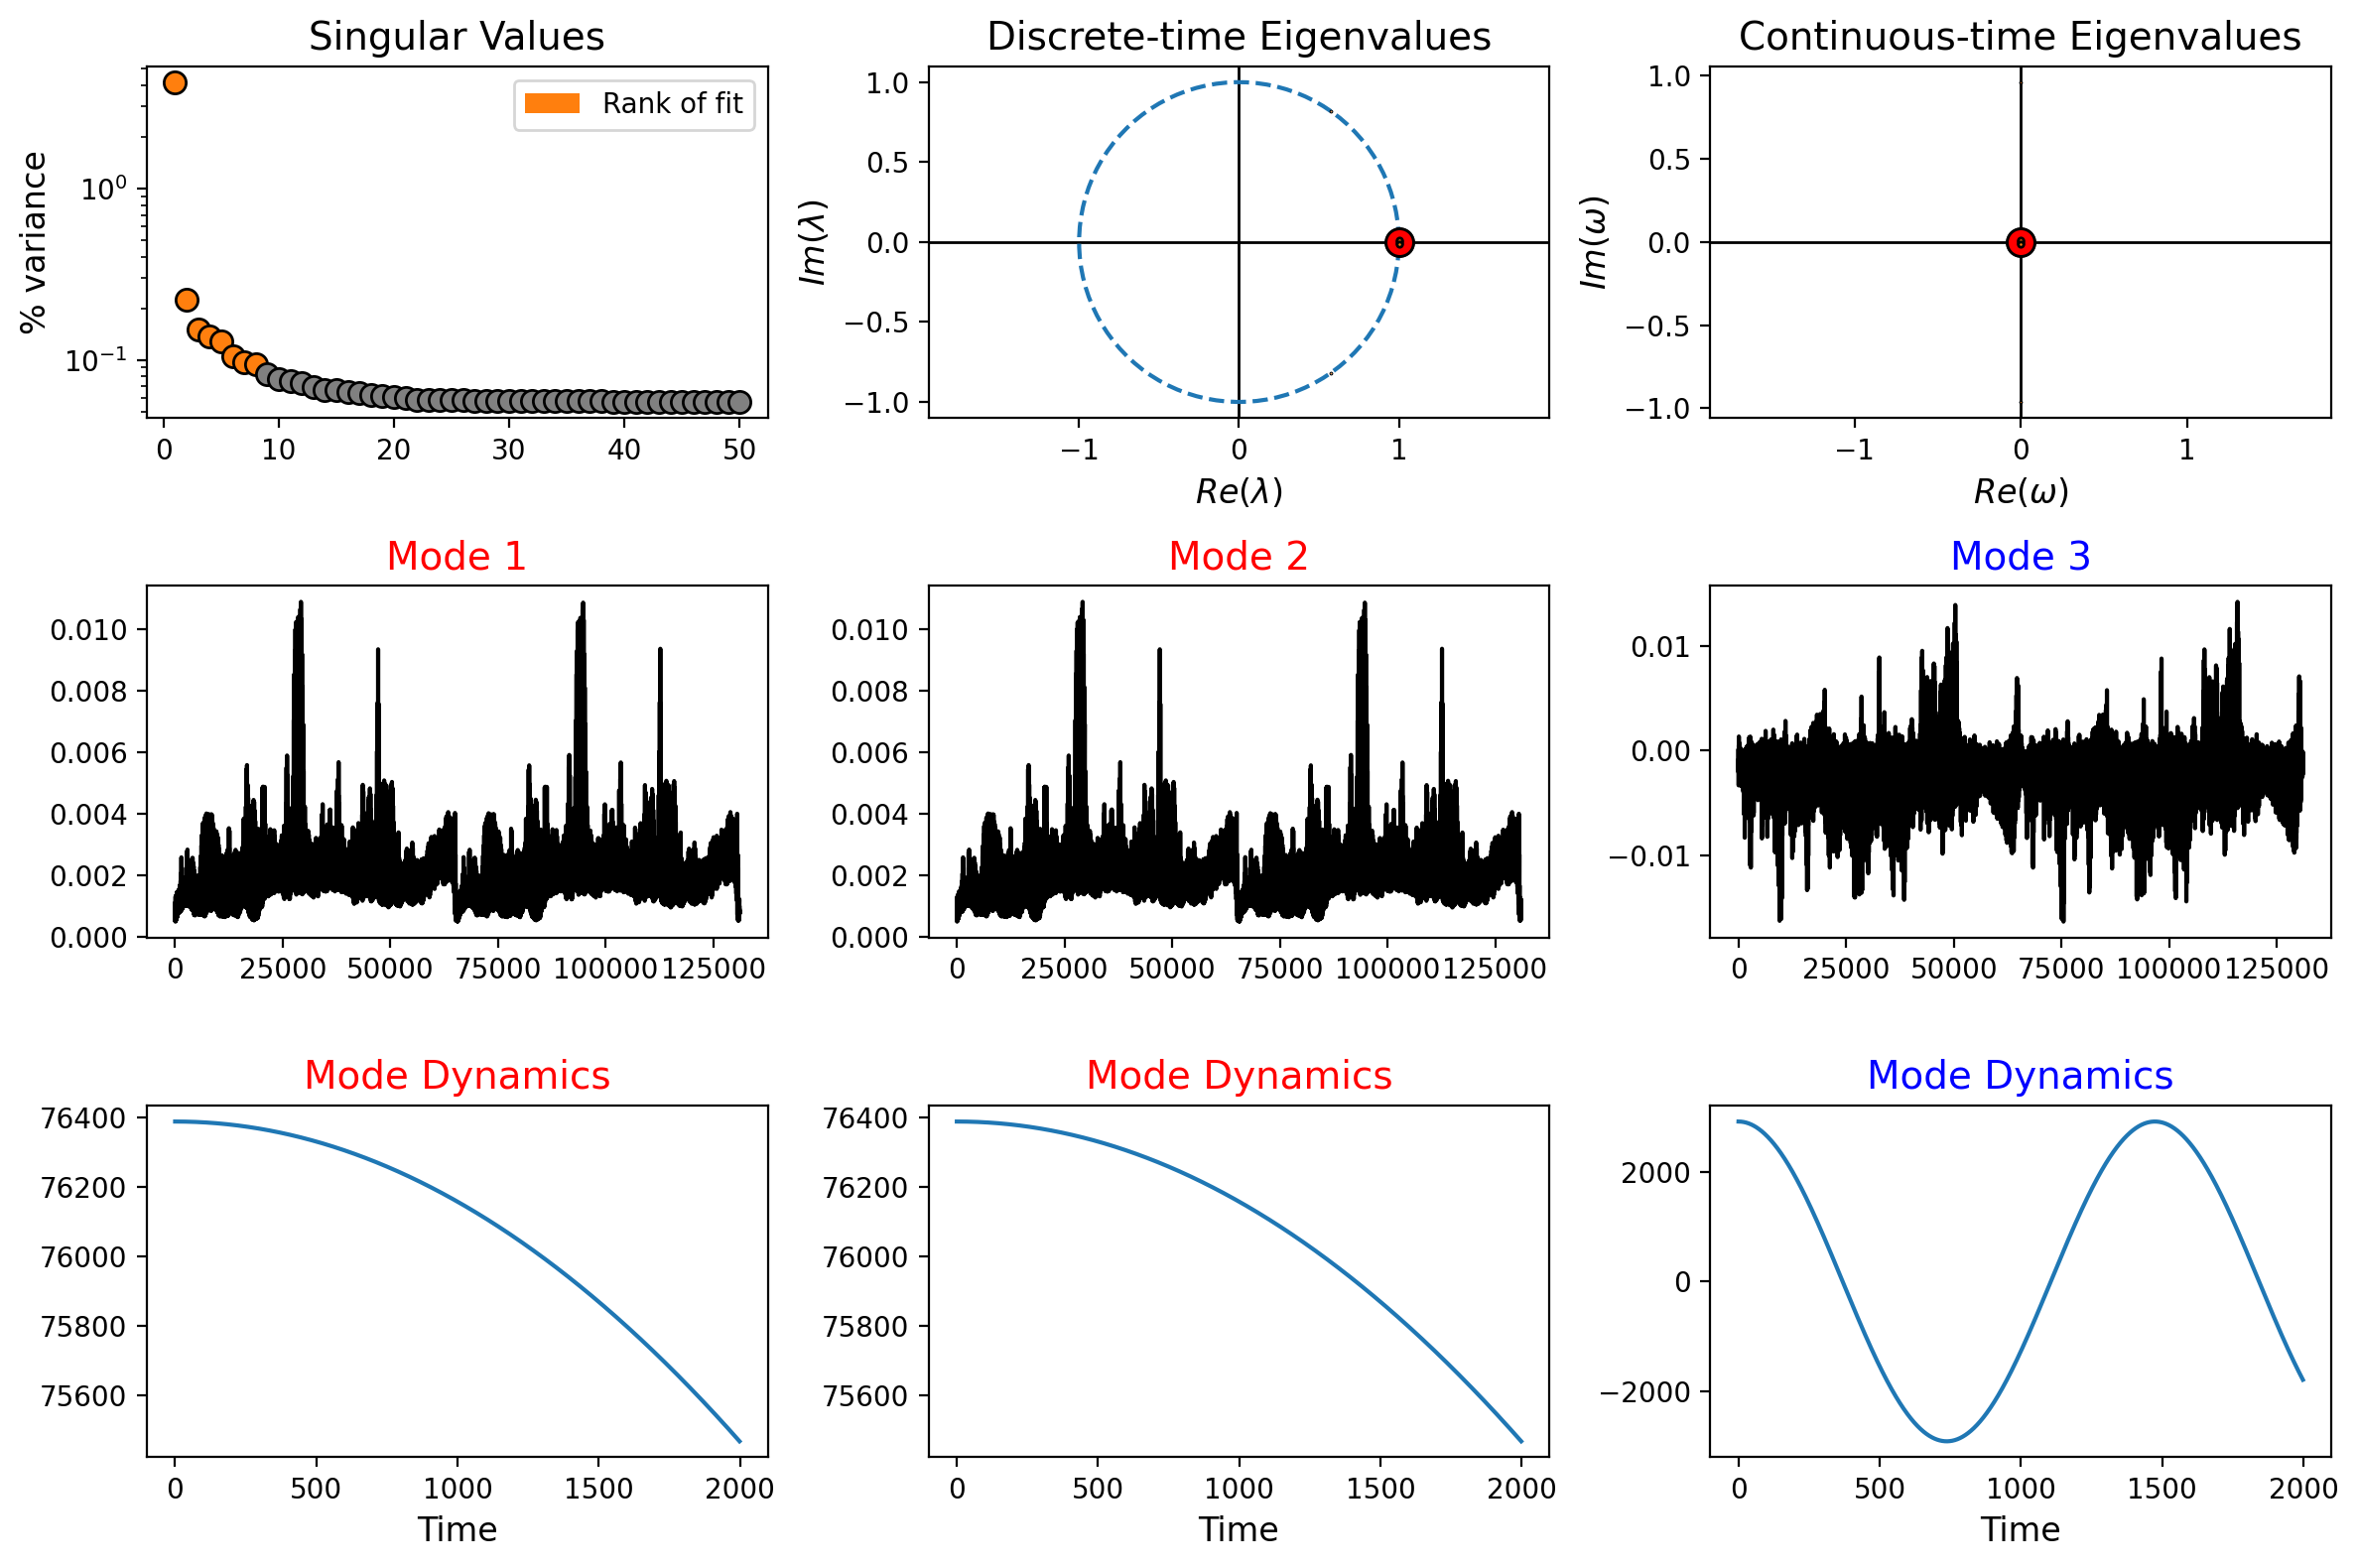

In [81]:
plot_summary(dmd, plot_semilogy=True)

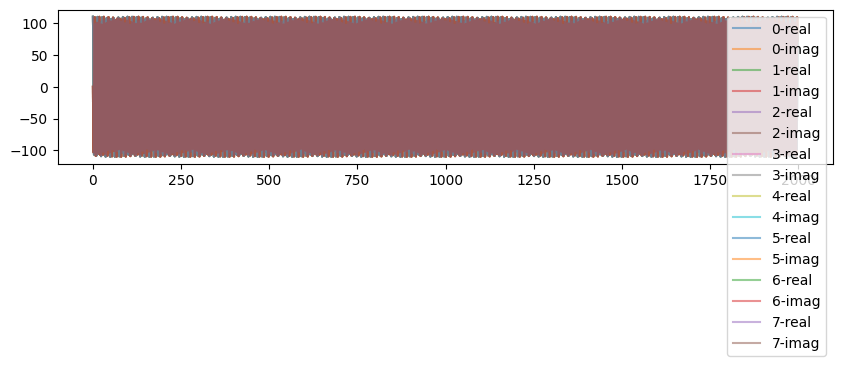

In [82]:
fig = plt.figure(figsize=(10, 2))

for i in range(dmd.svd_rank):
    plt.plot(dmd.dynamics[1].real, alpha=0.5, label=f"{i}-real")
    plt.plot(dmd.dynamics[1].imag, alpha=0.5, label=f"{i}-imag")
# plt.legend()
# plt.show()

# fig = plt.figure(figsize=(10, 2))
# plt.plot(dmd.dynamics[2].real, alpha=0.5, label="2-real")
# plt.plot(dmd.dynamics[2].imag, alpha=0.5, label="2-imag")
plt.legend()
plt.show()